# E11 · Ray tracing through a real lens

Follow light through two curved interfaces, compare a paraxial focus with finite-aperture rays, and separate geometric blur from diffraction.

<!-- course-motivation:start -->
## Why learn this?

**Why do the edge rays miss the focus?**

A thin-lens sketch predicts one focus, but a real spherical lens has thickness and accepts rays over a finite aperture. Before changing its shape, you need a model that follows where those rays actually go and explains which approximation caused the mismatch.

**What you gain:** Build a surface-by-surface ray tracer, locate a practical image plane and identify the geometric image errors that motivate lens design.
<!-- course-motivation:end -->

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Vectors, angles and surface normals:** Use a unit direction, a dot product and a quadratic surface equation. Used here: These identify the next intersection and the angle to its local normal. [Review: MIT OCW · Reflection and refraction, lecture 2](https://ocw.mit.edu/courses/2-71-optics-spring-2009/pages/lecture-slides/). Use lecture 2 to identify incident rays and interface normals. Review vector lengths and dot products before translating the picture into code.

**Python preparation:** Use small real vectors and arrays of ray positions; keep millimetres and degrees separate from array indices.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.

**Developed here:** Build the sequential ray-tracing algorithm and compare nonparaxial geometric rays with the small-angle lens prediction.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Find a forward surface intersection and apply Snell’s law using the local normal.
- Use a ray fan to test when a paraxial focal prediction stops being accurate.
- Explain why a geometric spot diagram does not establish diffraction-limited resolution.

**Model:** Sequential transmitted rays through two spherical or plane surfaces, with a real constant glass index and an object at infinity. The mechanical clear radius is 12 mm. No diffraction, polarization, Fresnel power weights, material dispersion or surface roughness is modeled. A geometric RMS spot is not a PSF or an MTF.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e11_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.11.7 | NumPy 2.4.6 | SciPy 1.17.1 | Matplotlib 3.11.2


## 1 · One ray, one interface

A ray is a position and a unit direction, not a wave amplitude. Throughout this lab,
vectors are **(x, y, z)**, lengths are **mm**, and z increases to the right in ray drawings.
A surface normal points into the transmitted medium. Split the incident unit vector
into normal and tangential parts: Snell's law scales the tangential part by n₁/n₂.
The new normal component makes the result a unit vector. A negative radicand means
total internal reflection, not a transmitted ray with a complex plotting coordinate.

**Predict:** from air into glass, does a 30° ray move toward or away from the normal?

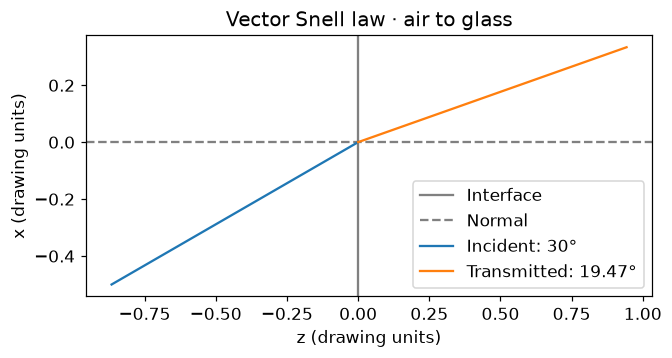

Normal incidence, scalar Snell law, TIR, and ray reversal checks passed.


In [2]:
from math import acos, cos, copysign, hypot, inf, isfinite, pi, sin, sqrt
def dot(a, b):
    return sum(x * y for x, y in zip(a, b))

def unit(v):
    length = sqrt(dot(v, v))
    if not isfinite(length) or length <= 0:
        raise ValueError("A ray direction must have a finite positive length.")
    return [x / length for x in v]

def refract(direction, normal, n_before, n_after):
    """Vector Snell law; normal is oriented into the transmitted medium."""
    d, normal = unit(direction), unit(normal)
    if dot(d, normal) < 0:
        normal = [-x for x in normal]
    cosine = max(0., min(1., dot(d, normal)))
    eta = n_before / n_after
    tangential = [d[i] - cosine * normal[i] for i in range(3)]
    radicand = 1 - eta * eta * dot(tangential, tangential)
    if radicand < -1e-12:
        return dict(status="tir", normal=normal, cos_incident=cosine)
    transmitted = sqrt(max(0., radicand))
    return dict(status="ok", direction=unit([eta * tangential[i] + transmitted * normal[i] for i in range(3)]),
                normal=normal, cos_incident=cosine, cos_transmitted=transmitted)

incoming = [sin(pi/6), 0., cos(pi/6)]
answer = refract(incoming, [0.,0.,1.], 1., 1.5)
theta_out = acos(answer["direction"][2])
assert abs(sin(pi/6)-1.5*sin(theta_out)) < 1e-13
assert refract([0.,0.,1.],[0.,0.,1.],1.,1.5)["direction"] == [0.,0.,1.]
assert refract([sin(pi/3),0.,cos(pi/3)],[0.,0.,1.],1.5,1.)["status"] == "tir"
reverse = refract([-v for v in answer["direction"]], [0.,0.,-1.], 1.5, 1.)
assert np.max(abs(np.array(reverse["direction"])+incoming)) < 1e-13
fig, ax = plt.subplots(figsize=(6,4))
ax.axvline(0,color="gray",label="Interface");ax.axhline(0,color="gray",ls="--",label="Normal")
ax.plot([-incoming[2],0],[-incoming[0],0],label="Incident: 30°")
ax.plot([0,answer["direction"][2]],[0,answer["direction"][0]],label=f"Transmitted: {np.rad2deg(theta_out):.2f}°")
ax.set(xlabel="z (drawing units)",ylabel="x (drawing units)",title="Vector Snell law · air to glass")
ax.set_aspect("equal",adjustable="box");ax.legend();show(fig,"01-one-interface")
print("Normal incidence, scalar Snell law, TIR, and ray reversal checks passed.")

## 2 · A sphere is not the same as its optical surface

A radius R has its centre at z = vertex + R. The surface is the spherical **cap
containing the vertex**. A line can meet the complete sphere twice: accepting any
positive root without checking the cap can send a ray to the far hemisphere.
At pupil radius ρ, the physical sag is R − sign(R)√(R²−ρ²).

**Predict:** at x = 6 mm on a surface with R = +50 mm, is the first surface point
near z = 0, or near z = 100 mm? The intersection routine also checks the clear radius.

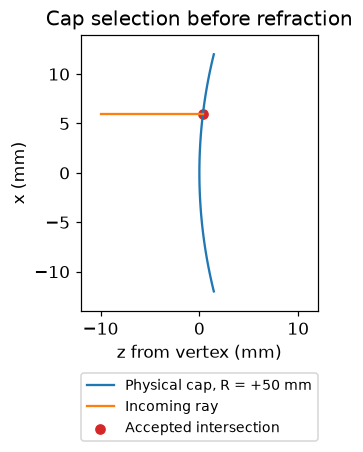

Near-cap sag: 0.36130541603657207 mm; rejected far-hemisphere root: 99.63869458396343 mm


In [3]:
def curvature(radius):
    return 0.0 if radius is None or not isfinite(radius) else 1.0 / radius

def surface_sag(radius, rho):
    c = curvature(radius)
    radicand = 1 - (c * rho) ** 2
    if radicand < -1e-12:
        return float("nan")
    return c * rho * rho / (1 + sqrt(max(0.0, radicand)))

def intersect_surface(origin, direction, vertex, radius, clear_radius=12.0):
    """Nearest forward intersection with the physical cap, never the far hemisphere."""
    direction = unit(direction)
    if curvature(radius) == 0:
        roots = [] if abs(direction[2]) < 1e-14 else [(vertex - origin[2]) / direction[2]]
    else:
        relative = [origin[0], origin[1], origin[2] - vertex - radius]
        b, c = 2 * dot(relative, direction), dot(relative, relative) - radius * radius
        disc = b * b - 4 * c
        if disc < -1e-10:
            return dict(status="missed")
        q = -.5 * (b + copysign(sqrt(max(0.0, disc)), b))
        roots = [q, c / q] if abs(q) > 1e-15 else [-b / 2]
    for t in sorted(roots):
        if t <= 1e-9:
            continue
        point = [o + t * v for o, v in zip(origin, direction)]
        rho = hypot(point[0], point[1])
        sag = surface_sag(radius, rho)
        if not isfinite(sag) or abs(point[2] - vertex - sag) > 1e-7 * max(1, abs(vertex), abs(point[2])):
            continue
        if rho > clear_radius + 1e-9:
            return dict(status="blocked", point=point, distance=t)
        normal = [0., 0., 1.] if curvature(radius) == 0 else unit([point[0], point[1], point[2] - vertex - radius])
        if dot(direction, normal) < 0:
            normal = [-x for x in normal]
        return dict(status="ok", point=point, distance=t, normal=normal)
    return dict(status="missed")

hit = intersect_surface([6.,0.,-10.],[0.,0.,1.],0.,50.,12.)
analytic_sag = 50.-np.sqrt(50.**2-6.**2)
assert hit["status"] == "ok" and abs(hit["point"][2]-analytic_sag) < 1e-12
assert intersect_surface([13.,0.,-10.],[0.,0.,1.],0.,50.,12.)["status"] == "blocked"
assert intersect_surface([0.,0.,-10.],[0.,0.,1.],4.,-50.,12.)["point"][2] == 4.
height = np.linspace(-12,12,121)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot([surface_sag(50.,abs(x)) for x in height],height,label="Physical cap, R = +50 mm")
ax.plot([-10,hit["point"][2]],[6,6],label="Incoming ray")
ax.scatter([hit["point"][2]],[6],color="tab:red",label="Accepted intersection")
ax.set(xlabel="z from vertex (mm)",ylabel="x (mm)",title="Cap selection before refraction",xlim=(-12,12),ylim=(-14,14))
ax.set_aspect("equal",adjustable="box");ax.legend(loc="upper center",bbox_to_anchor=(.5,-.2),fontsize=9);show(fig,"02-physical-cap")
print("Near-cap sag:",analytic_sag,"mm; rejected far-hemisphere root:",50+np.sqrt(50**2-6**2),"mm")

## 3 · Trace a pupil through two surfaces

The lens has R₁ = +50 mm, R₂ = −50 mm, thickness 4 mm and refractive index 1.5,
surrounded by air. Its mechanical clear radius is 12 mm. The entrance stop stays
at z = −5 mm in air. **Aperture** below is that stop's radius, not the lens diameter.
Each ray follows intersection → refraction → intersection → refraction → detector.
Pupil samples use equal-area annuli, so their equal weights approximate uniform illumination.

The paraxial thick-lens power predicts an image plane for an on-axis object at infinity.
An exact geometric bundle can cross at different z positions. A small RMS radius is
a statement about geometric rays; it is not an intensity PSF or an MTF.
**Predict:** what changes if you halve the entrance-stop radius but keep the detector fixed?

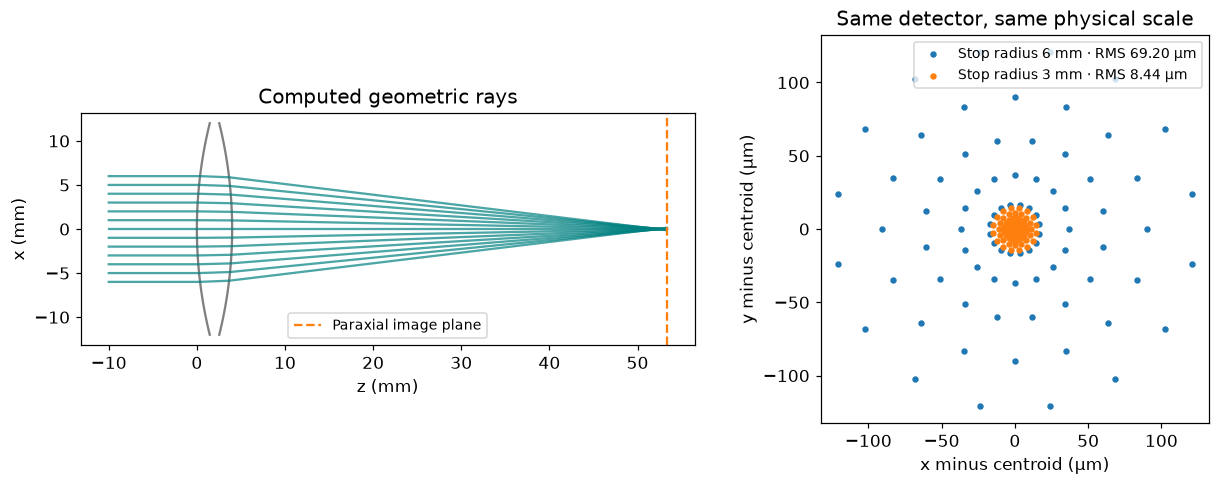

Paraxial EFL / back focal length / absolute image z: {'power': 0.019733333333333335, 'focal': 50.67567567567567, 'bfl': 49.32432432432432, 'image_z': 53.32432432432432}
Geometric RMS: 69.19565743770927 μm; accepted rays: 96 / 96


In [4]:
def make_lens(r1=50.0, r2=-50.0, thickness=4.0, index=1.5, clear_radius=12.0):
    if thickness <= 0 or index <= 0 or clear_radius <= 0:
        raise ValueError("Thickness, refractive index, and clear radius must be positive.")
    radii = [None if r is None or not isfinite(r) else float(r) for r in (r1, r2)]
    if any(r == 0 for r in radii):
        raise ValueError("Zero radius is not a plane; use None or infinity.")
    edge = thickness + surface_sag(radii[1], clear_radius) - surface_sag(radii[0], clear_radius)
    return dict(r1=radii[0], r2=radii[1], thickness=float(thickness), index=float(index),
                clear_radius=float(clear_radius), edge_thickness=edge)

def paraxial(lens):
    """Independent first-order thick-lens prediction, object at infinity in air."""
    n, d = lens["index"], lens["thickness"]
    c1, c2 = curvature(lens["r1"]), curvature(lens["r2"])
    power = (n - 1) * (c1 - c2 + (n - 1) * d * c1 * c2 / n)
    focal = 1 / power if abs(power) > 1e-15 else inf
    bfl = focal * (1 - (n - 1) * d * c1 / n)
    return dict(power=power, focal=focal, bfl=bfl, image_z=d + bfl)

def trace_ray(origin, direction, lens, image_z=None):
    point, direction = list(origin), unit(direction)
    points, surfaces = [point[:]], []
    for number, (vertex, radius, ni, nt) in enumerate([(0., lens["r1"], 1., lens["index"]),
            (lens["thickness"], lens["r2"], lens["index"], 1.)], 1):
        hit = intersect_surface(point, direction, vertex, radius, lens["clear_radius"])
        hit["surface"] = number
        surfaces.append(hit)
        if "point" in hit:
            points.append(hit["point"])
        if hit["status"] != "ok":
            return dict(status=hit["status"], points=points, surfaces=surfaces, failed_surface=number,
                        exit=None, direction=None, image=None)
        bent = refract(direction, hit["normal"], ni, nt)
        hit.update(n_before=ni, n_after=nt, incoming=direction, outgoing=bent.get("direction"))
        if bent["status"] != "ok":
            return dict(status=bent["status"], points=points, surfaces=surfaces, failed_surface=number,
                        exit=None, direction=None, image=None)
        point, direction = hit["point"], bent["direction"]
    image = None
    if image_z is not None:
        t = (image_z - point[2]) / direction[2] if abs(direction[2]) > 1e-14 else -1
        if t < 0:
            return dict(status="image_behind_lens", points=points, surfaces=surfaces,
                        exit=point, direction=direction, image=None)
        image = [p + t * v for p, v in zip(point, direction)]
        points.append(image)
    return dict(status="ok", points=points, surfaces=surfaces, exit=point, direction=direction, image=image)

def pupil_ray(x, y, field_deg, lens, image_z=None, launch_z=-10.0, pupil_z=-5.0):
    theta = field_deg * pi / 180
    direction = [sin(theta), 0., cos(theta)]
    origin = [x + (launch_z - pupil_z) * direction[0] / direction[2], y, launch_z]
    result = trace_ray(origin, direction, lens, image_z)
    result["pupil"] = [x, y]
    return result

def pupil_samples(aperture, rings=6, spokes=16):
    """Equal-area annuli, midpoint radial quadrature, equal weights per ray."""
    if aperture <= 0 or rings < 1 or spokes < 4:
        raise ValueError("Use a positive pupil and at least one ring/four spokes.")
    return [[aperture * sqrt((j + .5) / rings) * cos(2 * pi * (k + .5 * (j % 2)) / spokes),
             aperture * sqrt((j + .5) / rings) * sin(2 * pi * (k + .5 * (j % 2)) / spokes)]
            for j in range(rings) for k in range(spokes)]

def trace_bundle(lens, aperture, field_deg, image_z, rings=6, spokes=16):
    rays = [pupil_ray(x, y, field_deg, lens, image_z) for x, y in pupil_samples(aperture, rings, spokes)]
    accepted = [r for r in rays if r["status"] == "ok"]
    xy = [r["image"][:2] for r in accepted if r["image"] is not None]
    centroid = [sum(p[i] for p in xy) / len(xy) for i in range(2)] if xy else None
    rms = sqrt(sum(sum((p[i] - centroid[i]) ** 2 for i in range(2)) for p in xy) / len(xy)) if xy else None
    return dict(rays=rays, xy=xy, centroid=centroid, rms_mm=rms, requested=len(rays),
                accepted=len(accepted), throughput=len(accepted) / len(rays), field_deg=field_deg, image_z=image_z)

def best_image_plane(lens, aperture, fields=(0., 3., 6.), rings=6, spokes=16, bounds=(30., 90.)):
    """Minimize equal-field-weighted centroid RMS² over ONE common axial plane.

    In air after the second surface, x(z)=a+bz. Subtract the centroid separately
    within each field. Sum all field variances before solving the quadratic.
    This removes image displacement from the spot size, but never refocuses fields.
    """
    quadratic, linear = 0., 0.
    for field in fields:
        bundle = trace_bundle(lens, aperture, field, None, rings, spokes)
        accepted = [r for r in bundle["rays"] if r["status"] == "ok" and r["direction"][2] > 0]
        if not accepted:
            return max(bounds[0], min(bounds[1], paraxial(lens)["image_z"]))
        for axis in range(2):
            slopes = [r["direction"][axis] / r["direction"][2] for r in accepted]
            intercepts = [r["exit"][axis] - r["exit"][2] * b for r, b in zip(accepted, slopes)]
            bm, am = sum(slopes) / len(slopes), sum(intercepts) / len(intercepts)
            quadratic += sum((b - bm) ** 2 for b in slopes) / len(slopes)
            linear += sum((a - am) * (b - bm) for a, b in zip(intercepts, slopes)) / len(slopes)
    return max(bounds[0], min(bounds[1], -linear / quadratic)) if quadratic > 1e-20 else bounds[1]

lens = make_lens()
aperture, field = 6., 0.
first_order = paraxial(lens)
image_z = first_order["image_z"]
bundle = trace_bundle(lens,aperture,field,image_z)
assert bundle["accepted"] == bundle["requested"]
fig,ax = plt.subplots(1,2,figsize=(12,4.3))
for vertex,radius in [(0.,lens["r1"]),(lens["thickness"],lens["r2"])]:
    ax[0].plot([vertex+surface_sag(radius,abs(h)) for h in height],height,color="gray")
for h in np.linspace(-aperture,aperture,13):
    ray = pupil_ray(h,0.,field,lens,image_z)
    points=np.asarray(ray["points"])
    ax[0].plot(points[:,2],points[:,0],color="teal",alpha=.7)
ax[0].axvline(image_z,color="tab:orange",ls="--",label="Paraxial image plane")
ax[0].set(xlabel="z (mm)",ylabel="x (mm)",title="Computed geometric rays")
ax[0].set_aspect("equal",adjustable="box");ax[0].legend(fontsize=9)
for radius in [aperture,aperture/2]:
    b=trace_bundle(lens,radius,field,image_z)
    points=1000*(np.asarray(b["xy"])-b["centroid"])
    ax[1].scatter(points[:,0],points[:,1],s=10,label=f"Stop radius {radius:g} mm · RMS {1000*b['rms_mm']:.2f} μm")
ax[1].set(xlabel="x minus centroid (μm)",ylabel="y minus centroid (μm)",title="Same detector, same physical scale")
ax[1].set_aspect("equal",adjustable="box");ax[1].legend(fontsize=9)
show(fig,"03-pupil-bundle")
print("Paraxial EFL / back focal length / absolute image z:",first_order)
print("Geometric RMS:",1000*bundle["rms_mm"],"μm; accepted rays:",bundle["accepted"],"/",bundle["requested"])

## 4 · Test a ray model against independent predictions

Agreement between two plots is weak evidence. Here a ray close to the axis must
approach a thick-lens **ABCD matrix** prediction. Then reverse a full two-surface
ray: it must retrace both intersections and recover the original direction.
Finally refine the pupil quadrature without moving the lens or detector.

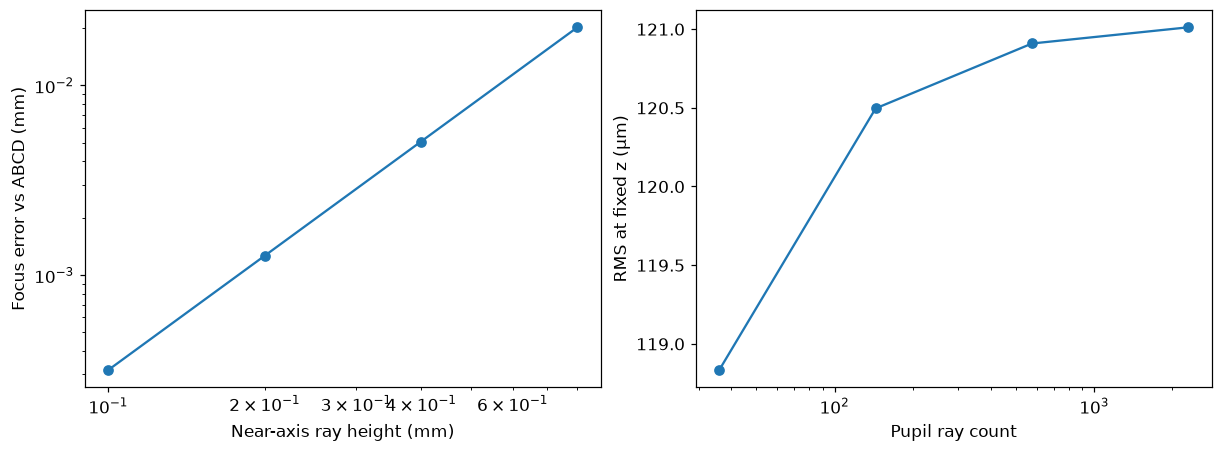

ABCD focus: 53.32432432432432 mm; near-axis focus errors: [0.02025935 0.00506352 0.0012658  0.00031644]
Pupil convergence: [(36, 0.11883393103800602), (144, 0.12049616809220018), (576, 0.12090866642543296), (2304, 0.12101160314513183)]
Full-ray reversibility passed.


In [5]:
n,d,R1,R2=lens["index"],lens["thickness"],lens["r1"],lens["r2"]
# Reduced-angle state (height, n*theta): surface power and translation are independent first-order optics.
S1=np.array([[1.,0.],[-(n-1)/R1,1.]])
T=np.array([[1.,d/n],[0.,1.]])
S2=np.array([[1.,0.],[-(1-n)/R2,1.]])
M=S2@T@S1
matrix_efl=-1/M[1,0];matrix_image=d-M[0,0]/M[1,0]
assert abs(matrix_efl-first_order["focal"])<1e-12
heights=np.array([.8,.4,.2,.1]);focus=[]
for h in heights:
    ray=pupil_ray(h,0.,0.,lens)
    focus.append(ray["exit"][2]-ray["exit"][0]*ray["direction"][2]/ray["direction"][0])
errors=abs(np.asarray(focus)-matrix_image)
assert np.all(errors[1:]<errors[:-1]/3.8)
forward=pupil_ray(4.,2.,6.,lens)
origin=np.asarray(forward["exit"])+3*np.asarray(forward["direction"])
direction=-np.asarray(forward["direction"])
for vertex,radius,ni,nt,expected in [(d,R2,1.,n,forward["surfaces"][1]["point"]),(0.,R1,n,1.,forward["surfaces"][0]["point"])]:
    hit=intersect_surface(origin,direction,vertex,radius,lens["clear_radius"])
    assert hit["status"]=="ok" and np.max(abs(np.asarray(hit["point"])-expected))<1e-10
    direction=np.asarray(refract(direction,hit["normal"],ni,nt)["direction"]);origin=hit["point"]
assert np.max(abs(direction+np.asarray(forward["surfaces"][0]["incoming"])))<1e-12
counts=[];rms=[]
for rings,spokes in [(3,12),(6,24),(12,48),(24,96)]:
    refined=trace_bundle(lens,6.,6.,image_z,rings,spokes)
    counts.append(refined["requested"]);rms.append(refined["rms_mm"])
assert abs(rms[-2]/rms[-1]-1)<.01
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].loglog(heights,errors,"o-");ax[0].set(xlabel="Near-axis ray height (mm)",ylabel="Focus error vs ABCD (mm)")
ax[1].semilogx(counts,np.array(rms)*1000,"o-");ax[1].set(xlabel="Pupil ray count",ylabel="RMS at fixed z (μm)")
show(fig,"04-independent-checks")
print("ABCD focus:",matrix_image,"mm; near-axis focus errors:",errors)
print("Pupil convergence:",list(zip(counts,rms)));print("Full-ray reversibility passed.")

## Optional extension · A geometric spot is not the diffraction limit

For each aperture, choose its best **single on-axis** geometric image plane.
Compare the trend with the approximate Airy first-zero radius 0.61 λ/NA, using
NA ≈ aperture/EFL in air. These are different measures, RMS and first-zero radius:
do not add them or treat their crossing as an exact wave-optical prediction.
The ray calculation has no wavelength. A shrinking ray spot cannot prove that
a sufficiently small aperture will yield unlimited image resolution.

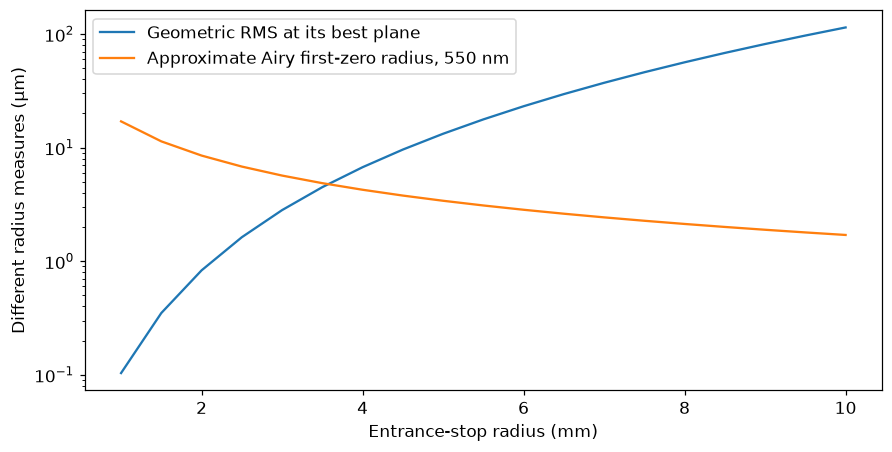

In [6]:
radii=np.linspace(1.,10.,19);geometric=[];airy=[]
for radius in radii:
    plane=best_image_plane(lens,radius,[0.])
    geometric.append(1000*trace_bundle(lens,radius,0.,plane)["rms_mm"])
    airy.append(1000*.61*.00055/(radius/first_order["focal"]))
fig,ax=plt.subplots(figsize=(8,4))
ax.semilogy(radii,geometric,label="Geometric RMS at its best plane")
ax.semilogy(radii,airy,label="Approximate Airy first-zero radius, 550 nm")
ax.set(xlabel="Entrance-stop radius (mm)",ylabel="Different radius measures (μm)");ax.legend()
show(fig,"05-geometric-versus-wave")

## A short lab report

**1. Follow one ray.** Report both intersections, the local incidence angles and the two refracted directions. Check Snell’s law numerically.

**2. Test the paraxial limit.** Reduce the entrance radius at fixed index and compare the traced on-axis focus with the independent thick-lens prediction.

**3. Separate image position and blur.** At two field angles, report the centroid and RMS radius with the same image plane and pupil sampling.

### Worked reasoning

**Follow one ray.** Use the sphere centre to construct each normal. Check forward distance, cap membership and the unit length of every direction.

**Test the paraxial limit.** The narrow-bundle limit approaches the paraxial back focal distance. Report the image coordinate from the first vertex separately from effective focal length.

**Separate image position and blur.** Centroid motion locates the image; spread about that centroid is geometric blur. Neither number alone measures diffraction-limited resolution.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [MIT OCW · Refraction, paraxial imaging and thick lenses (lectures 2–5)](https://ocw.mit.edu/courses/2-71-optics-spring-2009/pages/lecture-slides/)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [7]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 5 figures in e11_figures.zip


/tmp/optics-notebooks-5i22xxhb/E11/e11_figures.zip